In [1]:

!pip -q install tensorflow scikit-learn pandas matplotlib requests


In [11]:
import requests
import pandas as pd
from datetime import date, timedelta
from urllib.parse import quote

articles = [
    "Artificial_intelligence",
    "Machine_learning",
    "Python_(programming_language)",
    "Internet",
    "Data_science"
]

end_date = date.today() - timedelta(days=1)
start_date = end_date - timedelta(days=399)
dates = pd.date_range(start_date, end_date, freq="D")

traffic = pd.DataFrame(index=dates)
traffic.index.name = "Date"

headers = {
    "User-Agent": "StudentTrafficProject/1.0"
}

for article in articles:
    records = []
    current = start_date

    while current <= end_date:
        last = min(current + timedelta(days=300), end_date)

        url = (
            "https://wikimedia.org/api/rest_v1/metrics/pageviews/"
            f"per-article/en.wikipedia/all-access/all-agents/"
            f"{quote(article, safe='')}/daily/"
            f"{current:%Y%m%d}/{last:%Y%m%d}"
        )

        r = requests.get(url, headers=headers, timeout=60)
        r.raise_for_status()

        for item in r.json().get("items", []):
            day = pd.to_datetime(item["timestamp"][:8],
                                 format="%Y%m%d")
            records.append((day, item["views"]))

        current = last + timedelta(days=1)

    s = pd.Series(
        [v for d, v in records],
        index=[d for d, v in records],
        dtype=float
    )
    traffic[article] = s[~s.index.duplicated()]

traffic = traffic.reindex(dates)
traffic = traffic.interpolate(method="time").ffill().bfill()
traffic = traffic.fillna(0).clip(lower=0).round().astype(int)

traffic["Total_Pageviews"] = traffic[articles].sum(axis=1)
traffic.to_csv("website_traffic.csv")

print("Dataset created!")
print("Shape:", traffic.shape)
display(traffic.head())

Dataset created!
Shape: (400, 6)


,Artificial_intelligence,Machine_learning,Python_(programming_language),Internet,Data_science,Total_Pageviews
Date,,,,,,
2025-09-17,24180,4792,14429,8545,1103,53049
2025-09-18,22393,5280,15412,9269,1232,53586
2025-09-19,22106,5465,15286,8210,1177,52244
2025-09-20,17611,4030,13403,7669,882,43595
2025-09-21,16240,3616,11077,7492,859,39284


In [12]:
print(traffic.isnull().sum())

Artificial_intelligence          0
Machine_learning                 0
Python_(programming_language)    0
Internet                         0
Data_science                     0
Total_Pageviews                  0
dtype: int64


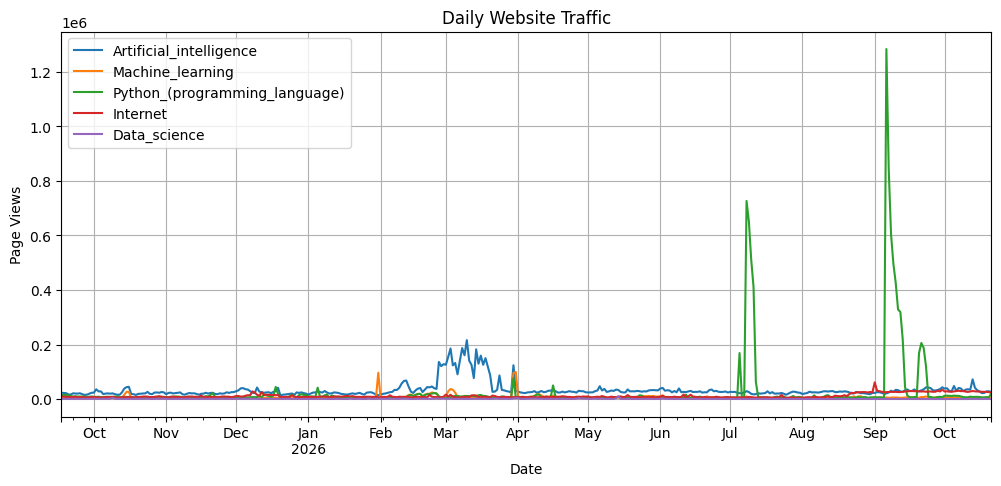

In [13]:
import matplotlib.pyplot as plt

traffic[articles].plot(figsize=(12, 5))
plt.title("Daily Website Traffic")
plt.xlabel("Date")
plt.ylabel("Page Views")
plt.grid(True)
plt.show()

In [21]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout

data = traffic[articles].values.astype(float)
split = int(len(data) * 0.8)
window = 30

scaler = MinMaxScaler()
scaler.fit(data[:split])
scaled = scaler.transform(data)

X_train, y_train = [], []
for i in range(window, split):
    X_train.append(scaled[i-window:i])
    y_train.append(scaled[i])

X_test, y_test = [], []
for i in range(split, len(data)):
    X_test.append(scaled[i-window:i])
    y_test.append(scaled[i])

X_train, y_train = np.array(X_train), np.array(y_train)
X_test, y_test = np.array(X_test), np.array(y_test)

model = Sequential([
    LSTM(32, input_shape=(window, len(articles))),
    Dropout(0.2),
    Dense(len(articles))
])

model.compile(optimizer="adam", loss="mse")

model.fit(
    X_train, y_train,
    epochs=30,
    batch_size=16,
    shuffle=False,
    verbose=1
)

print("Training completed!")

Epoch 1/30


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


19/19 ━━━━━━━━━━━━━━━━━━━━ 2s 11ms/step - loss: 0.0199
Epoch 2/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0145
Epoch 3/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0125
Epoch 4/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0122
Epoch 5/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0111
Epoch 6/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0105
Epoch 7/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0104
Epoch 8/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0100
Epoch 9/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0099
Epoch 10/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0097
Epoch 11/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0097
Epoch 12/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0095
Epoch 13/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0094
Epoch 14/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - loss: 0.0093
Epoch 15/30
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - loss: 0.0092
Epoch 16/30
19/

In [22]:
pred = model.predict(X_test)

actual = scaler.inverse_transform(y_test)
predicted = scaler.inverse_transform(pred)

print("MAE:", mean_absolute_error(actual, predicted))
print("RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
MAE: 15870.79313155502
RMSE: 75711.74879781733


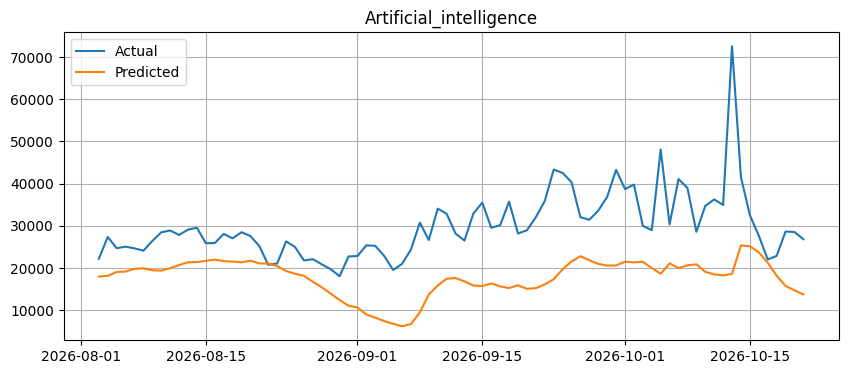

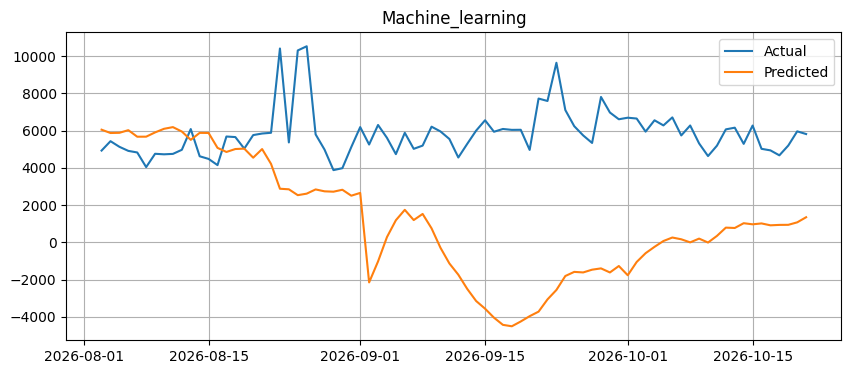

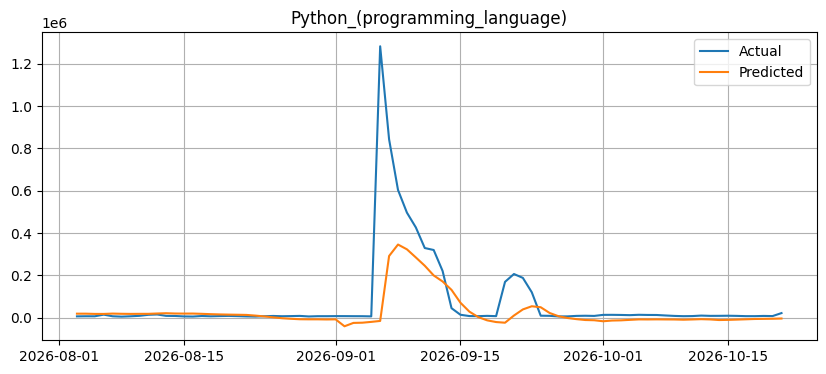

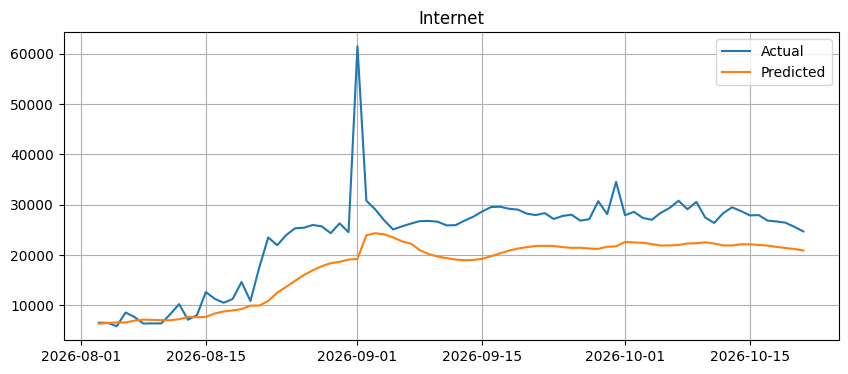

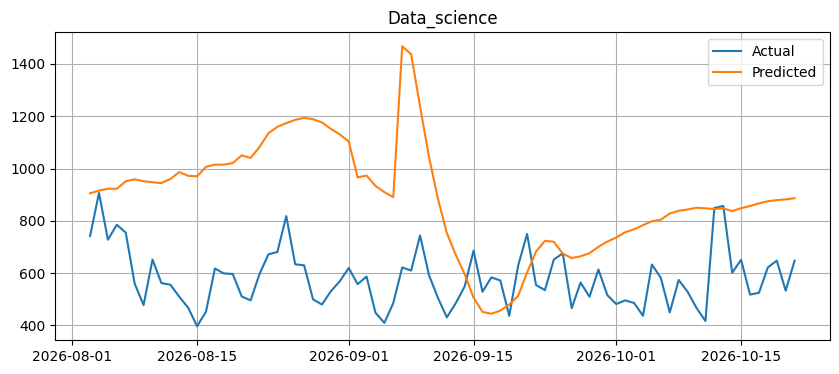

In [23]:
test_dates = traffic.index[split:]

for i, article in enumerate(articles):
    plt.figure(figsize=(10, 4))
    plt.plot(test_dates, actual[:, i], label="Actual")
    plt.plot(test_dates, predicted[:, i], label="Predicted")
    plt.title(article)
    plt.legend()
    plt.grid(True)
    plt.show()

In [24]:
last_window = scaled[-window:].copy()
future = []

for _ in range(7):
    p = model.predict(
        last_window.reshape(1, window, len(articles)),
        verbose=0
    )[0]
    future.append(p)
    last_window = np.vstack([last_window[1:], p])

future = scaler.inverse_transform(np.array(future))
future = np.maximum(future, 0).round().astype(int)

future_dates = pd.date_range(
    traffic.index[-1] + pd.Timedelta(days=1),
    periods=7
)

forecast = pd.DataFrame(
    future, index=future_dates, columns=articles
)
forecast["Total_Pageviews"] = forecast.sum(axis=1)

display(forecast)
forecast.to_csv("future_traffic_forecast.csv")

,Artificial_intelligence,Machine_learning,Python_(programming_language),Internet,Data_science,Total_Pageviews
2026-10-22,12946,1606,0,20541,894,35987
2026-10-23,10156,1925,0,19653,876,32610
2026-10-24,7566,2141,0,18777,862,29346
2026-10-25,4995,2292,0,17933,855,26075
2026-10-26,2508,2407,1001,17127,850,23893
2026-10-27,150,2502,2831,16363,848,22694
2026-10-28,0,2580,4739,15643,846,23808


In [25]:
from google.colab import files

files.download("website_traffic.csv")
files.download("future_traffic_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [19]:
import pandas as pd

traffic = pd.read_csv(
    "/content/website_traffic.csv",
    index_col=0,
    parse_dates=True
)

print(traffic.shape)
display(traffic.head())

(400, 6)


,Artificial_intelligence,Machine_learning,Python_(programming_language),Internet,Data_science,Total_Pageviews
Date,,,,,,
2025-09-17,24180,4792,14429,8545,1103,53049
2025-09-18,22393,5280,15412,9269,1232,53586
2025-09-19,22106,5465,15286,8210,1177,52244
2025-09-20,17611,4030,13403,7669,882,43595
2025-09-21,16240,3616,11077,7492,859,39284


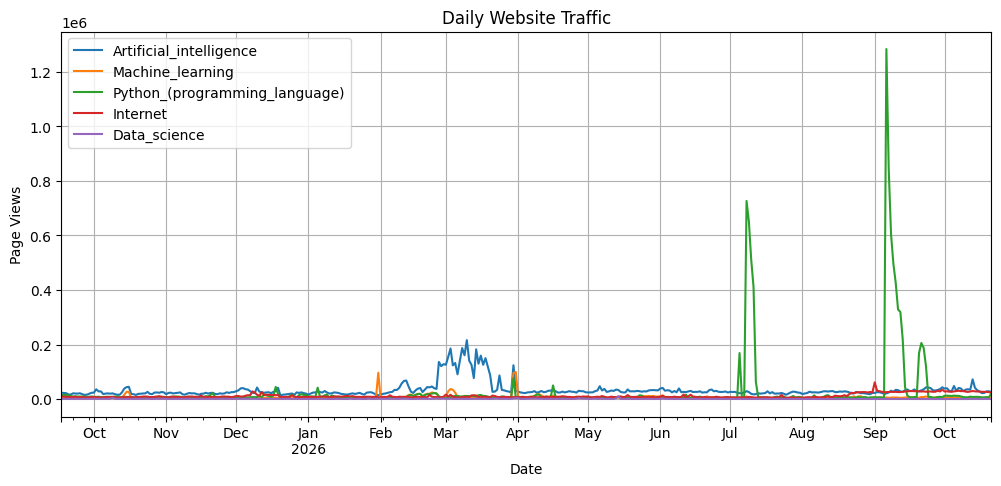

In [20]:
import matplotlib.pyplot as plt

traffic[articles].plot(figsize=(12, 5))
plt.title("Daily Website Traffic")
plt.xlabel("Date")
plt.ylabel("Page Views")
plt.grid(True)
plt.show()